# Data Exploration

### Loading Data

We will import kagglehub, and load the smaller csv training and testing files.

In [1]:
import sys

print(sys.executable)

c:\Users\madis\Documents\ADS2002-Melanoma\.venv\Scripts\python.exe


In [2]:
import kagglehub


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math as m

In [4]:
plt.rcParams["font.family"] = 'Verdana'

In [5]:
# Import code from module

from melanoma_detection.data import get_competition_file, load_train_metadata, load_test_metadata

In [6]:
# load the training and testing sets of data


# train_df = load_train_metadata()

# test_df = load_test_metadata()


train_df = pd.read_csv("../data/train_labels.csv")

test_df = pd.read_csv("../data/test_labels.csv")    





In [7]:
train_df

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
1,ISIC_0074542,IP_4698288,male,25.0,lower extremity,unknown,benign,0
2,ISIC_0076545,IP_9802602,male,55.0,upper extremity,unknown,benign,0
3,ISIC_0082348,IP_7684360,male,55.0,torso,unknown,benign,0
4,ISIC_0085172,IP_1705144,female,50.0,lower extremity,unknown,benign,0
...,...,...,...,...,...,...,...,...
6859,ISIC_9988492,IP_8173459,female,50.0,torso,unknown,benign,0
6860,ISIC_9990676,IP_3686214,female,55.0,lower extremity,nevus,benign,0
6861,ISIC_9991394,IP_2321962,female,30.0,torso,unknown,benign,0
6862,ISIC_9991967,IP_2507276,male,70.0,lower extremity,nevus,benign,0


### Data structure

Check the shape, columns, info, summary, number of duplicates, null entries, and datatypes.

In [14]:
train_df.head(50)

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
1,ISIC_0074542,IP_4698288,male,25.0,lower extremity,unknown,benign,0
2,ISIC_0076545,IP_9802602,male,55.0,upper extremity,unknown,benign,0
3,ISIC_0082348,IP_7684360,male,55.0,torso,unknown,benign,0
4,ISIC_0085172,IP_1705144,female,50.0,lower extremity,unknown,benign,0
5,ISIC_0086349,IP_2825529,female,55.0,torso,nevus,benign,0
6,ISIC_0086632,IP_2114130,male,40.0,torso,unknown,benign,0
7,ISIC_0087297,IP_5389392,male,55.0,torso,unknown,benign,0
8,ISIC_0089401,IP_7948039,female,25.0,torso,unknown,benign,0
9,ISIC_0091016,IP_4042098,male,40.0,torso,nevus,benign,0


In [10]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6864 entries, 0 to 6863
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   image_name                     6864 non-null   str    
 1   patient_id                     6864 non-null   str    
 2   sex                            6864 non-null   str    
 3   age_approx                     6864 non-null   float64
 4   anatom_site_general_challenge  6668 non-null   str    
 5   diagnosis                      6864 non-null   str    
 6   benign_malignant               6864 non-null   str    
 7   target                         6864 non-null   int64  
dtypes: float64(1), int64(1), str(6)
memory usage: 429.1 KB


In [11]:
train_df.describe()

,age_approx,target
count,6864.000000,6864.000000
mean,48.944493,0.018648
std,14.401600,0.135288
min,15.000000,0.000000
25%,40.000000,0.000000
50%,50.000000,0.000000
75%,60.000000,0.000000
max,90.000000,1.000000


Check all value counts

In [12]:
columns = ['sex','age_approx', 'anatom_site_general_challenge','diagnosis', 'benign_malignant','target']

for col in columns:

    counts = train_df[col].fillna('Missing').value_counts(dropna=False)

    proportions = train_df[col].fillna('Missing').value_counts(normalize=True) * 100
    print()
    print(f'+++++++++ {col} counts +++++++++')
    print(counts)

    print(f'+++++++++ {col} proportions +++++++++')
    print(proportions)


+++++++++ sex counts +++++++++
sex
female    3553
male      3311
Name: count, dtype: int64
+++++++++ sex proportions +++++++++
sex
female    51.762821
male      48.237179
Name: proportion, dtype: float64

+++++++++ age_approx counts +++++++++
age_approx
55.0    1011
45.0     866
50.0     804
60.0     768
40.0     675
65.0     490
30.0     483
35.0     465
25.0     413
70.0     401
75.0     180
20.0     169
80.0      85
85.0      20
15.0      18
90.0      16
Name: count, dtype: int64
+++++++++ age_approx proportions +++++++++
age_approx
55.0    14.729021
45.0    12.616550
50.0    11.713287
60.0    11.188811
40.0     9.833916
65.0     7.138695
30.0     7.036713
35.0     6.774476
25.0     6.016900
70.0     5.842075
75.0     2.622378
20.0     2.462121
80.0     1.238345
85.0     0.291375
15.0     0.262238
90.0     0.233100
Name: proportion, dtype: float64

+++++++++ anatom_site_general_challenge counts +++++++++
anatom_site_general_challenge
torso              3440
lower extremity    1650


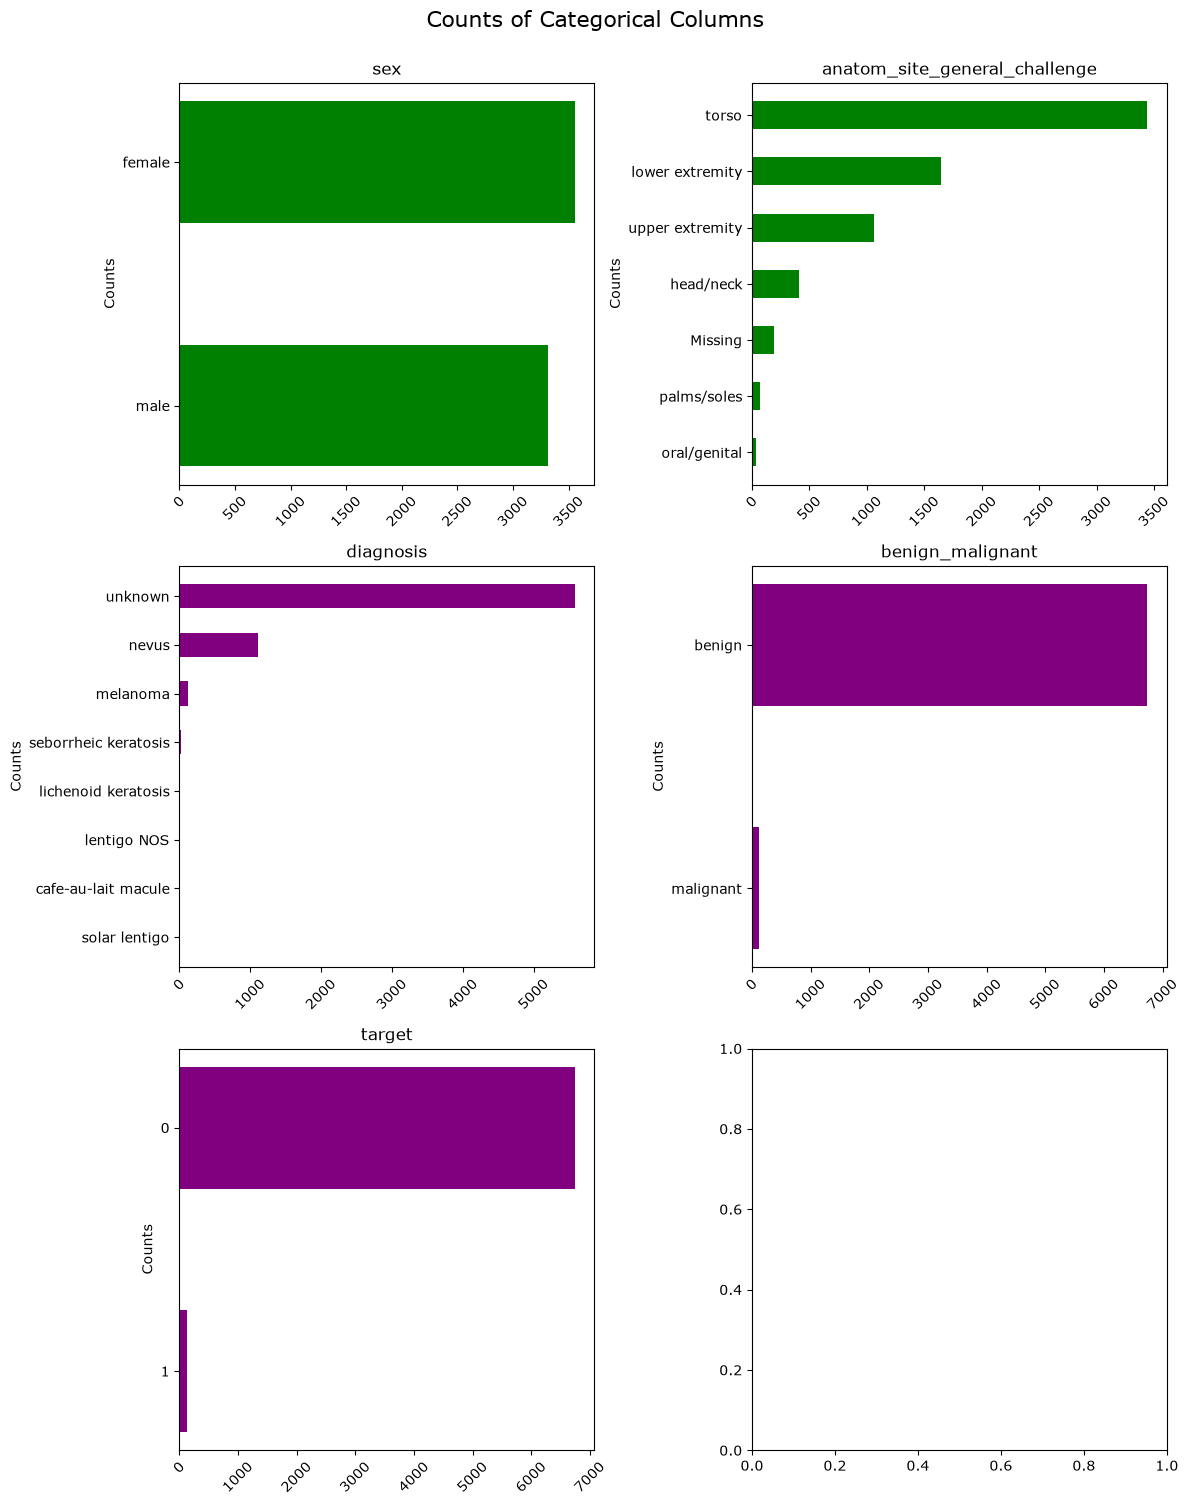

In [16]:
cat_cols = ['sex', 'anatom_site_general_challenge','diagnosis', 'benign_malignant','target']

colours = ['green','green','purple','purple','purple']
n_cols = 2
n_rows = m.ceil(len(cat_cols)/n_cols)



fig, axes = plt.subplots(n_rows, n_cols,figsize= (12, 5 * n_rows))

axes = axes.flatten()



for ax, col, c in zip(axes, cat_cols, colours):
    vals = train_df[col].fillna("Missing").astype(str).value_counts(dropna=False)


    ax.barh(vals.index, vals.values, height = 0.5, align='center', color = c)

    ax.set_title(col, fontweight=400)
    ax.set_ylabel("Counts")
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

    ax.invert_yaxis()

fig.suptitle("Counts of Categorical Columns", y = 1, size=16)
plt.subplots_adjust(hspace=0.9)
plt.tight_layout()



Findings:

